# Stage-1 exploration

Four Stage-1 seeders (`naive_pos`, `naive_abs`, `adaptive_nec`, `seqlets`); the rest of the two-stage pipeline is identical. Raw ISM maps, K562 model, 83 sequences.

Same metrics as the benchmark — **Sufficiency** (recovery, % of WT), **Necessity** (% of WT), **footprint** (bp) — but **stratified by activity class**, focused on whether a better seed lets us capture **repressors** (where the naive positive tail is blind).

Note: a few sequences have a tiny WT signal, so their %-of-WT ratio explodes (the 400% dots). Stats below use medians/IQR (robust to those); the scatter clips the view to keep it readable.

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

s = pd.read_csv(Path('results') / 'seed_comparison.csv')
ORDER = [v for v in ['naive_pos', 'naive_abs', 'adaptive_nec', 'seqlets', 'signed_nec', 'abs_nec'] if v in set(s.variant)]
C = {'naive_pos': '#9467bd', 'naive_abs': '#1f77b4', 'adaptive_nec': '#2ca02c',
     'seqlets': '#ff7f0e', 'signed_nec': '#d62728', 'abs_nec': '#8c564b'}
BINS = ['repressive', 'neutral', 'activating']
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})
pct = plt.FuncFormatter(lambda v, _: f'{v:.0%}')

# recovery = Sufficiency (% WT), nec_fraction = Necessity (% WT), total_bp = footprint
s.pivot_table(index='variant', columns='activity_bin', values='recovery',
              aggfunc='median').loc[ORDER, BINS].round(3).rename_axis('median Sufficiency')

activity_bin,repressive,neutral,activating
median Sufficiency,,,
naive_pos,1.026,0.984,0.938
naive_abs,1.032,0.966,0.938
adaptive_nec,1.016,1.000,0.947
seqlets,1.020,1.048,0.949
signed_nec,0.924,0.966,0.938
abs_nec,0.944,0.942,0.942


## Sufficiency vs footprint — stratified by activity class

One panel per class. Faint = per-sequence (clipped into view); big marker + IQR cross = median per variant. 90% target dashed. The repressive panel is the one that matters for the goal.

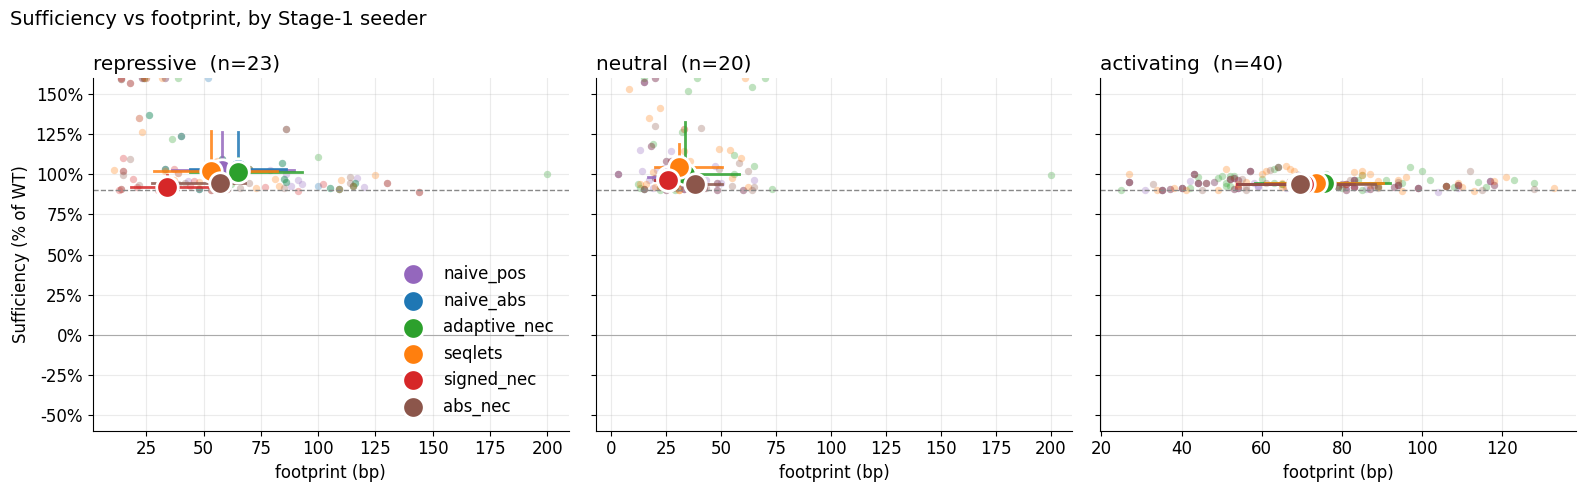

In [3]:
YLIM = (-0.6, 1.6)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, b in zip(axes, BINS):
    sb = s[s.activity_bin == b]
    for v in ORDER:
        g = sb[sb.variant == v]
        ax.scatter(g.total_bp, g.recovery.clip(*YLIM), s=28, alpha=0.3, lw=0, color=C[v])
    for v in ORDER:
        g = sb[sb.variant == v]
        mx, my = g.total_bp.median(), g.recovery.median()
        ax.plot([g.total_bp.quantile(.25), g.total_bp.quantile(.75)], [my, my], color=C[v], lw=2, alpha=.85)
        ax.plot([mx, mx], [g.recovery.quantile(.25), g.recovery.quantile(.75)], color=C[v], lw=2, alpha=.85)
        ax.scatter([mx], [np.clip(my, *YLIM)], s=240, color=C[v], edgecolor='white', lw=2, zorder=6,
                   label=v if ax is axes[0] else None)
    ax.axhline(0.90, ls='--', color='#888', lw=1); ax.axhline(0, color='#aaa', lw=0.8)
    ax.set_ylim(*YLIM); ax.yaxis.set_major_formatter(pct)
    ax.set_xlabel('footprint (bp)'); ax.set_title(f'{b}  (n={sb.seq_id.nunique()})', loc='left')
    ax.grid(alpha=0.25)
axes[0].set_ylabel('Sufficiency (% of WT)')
axes[0].legend(frameon=False, loc='lower right')
fig.suptitle('Sufficiency vs footprint, by Stage-1 seeder', x=0.01, ha='left', fontsize=14)
plt.tight_layout(); plt.show()

## Necessity & Sufficiency by activity class

Median % of WT per variant, split by class (bars = median, whisker = IQR). Does any seed raise Necessity/Sufficiency on **repressive** sequences?

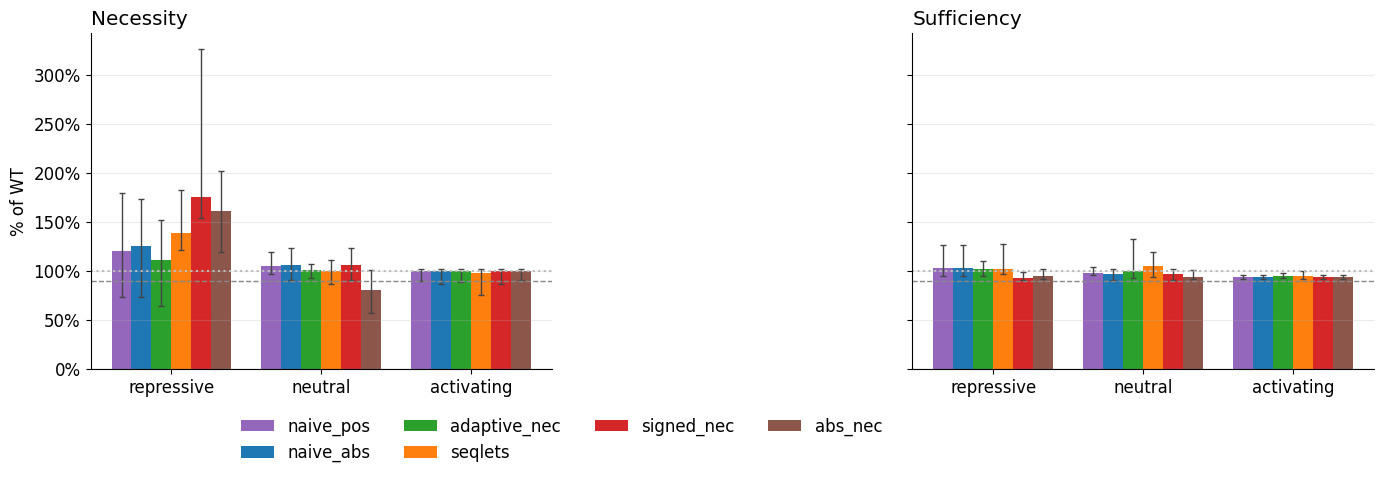

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
w = 0.8 / len(ORDER); x = np.arange(len(BINS))
for ax, col, title in zip(axes, ['nec_fraction', 'recovery'], ['Necessity', 'Sufficiency']):
    for i, v in enumerate(ORDER):
        g = s[s.variant == v]
        med = np.array([g[g.activity_bin == b][col].median() for b in BINS])
        lo = np.array([g[g.activity_bin == b][col].quantile(.25) for b in BINS])
        hi = np.array([g[g.activity_bin == b][col].quantile(.75) for b in BINS])
        xi = x + i * w
        ax.bar(xi, med, w, color=C[v], label=v if ax is axes[0] else None)
        ax.errorbar(xi, med, yerr=[np.clip(med - lo, 0, None), np.clip(hi - med, 0, None)],
                    fmt='none', ecolor='#444', elinewidth=1, capsize=2)
    ax.axhline(1.0, ls=':', color='#bbb'); ax.axhline(0.9, ls='--', color='#888', lw=1)
    ax.axhline(0, color='#888', lw=0.8)
    ax.set_xticks(x + w * (len(ORDER) - 1) / 2); ax.set_xticklabels(BINS)
    ax.yaxis.set_major_formatter(pct); ax.set_title(title, loc='left'); ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('% of WT')
axes[0].legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(1.02, -0.1))
plt.tight_layout(); plt.show()

## How aligned are the four seeders?

Since the final metrics are robust to the seed, do the variants annotate the *same thing*? Pooling every position (83 seqs × 200 bp), each labeled per variant as none / core / flank / context:

- **IoU** — do they call the same bp at all?
- **type agreement** — where both annotate, do they assign the same core/flank/context label?
- **coverage consensus** — of positions any variant calls, how many of the four agree.

The naive pair is near-interchangeable (IoU 0.81, type 0.95); `adaptive_nec` / `seqlets` are the outliers (~0.62 IoU). ~47% of annotated bp are called by all four, ~24% by only one.

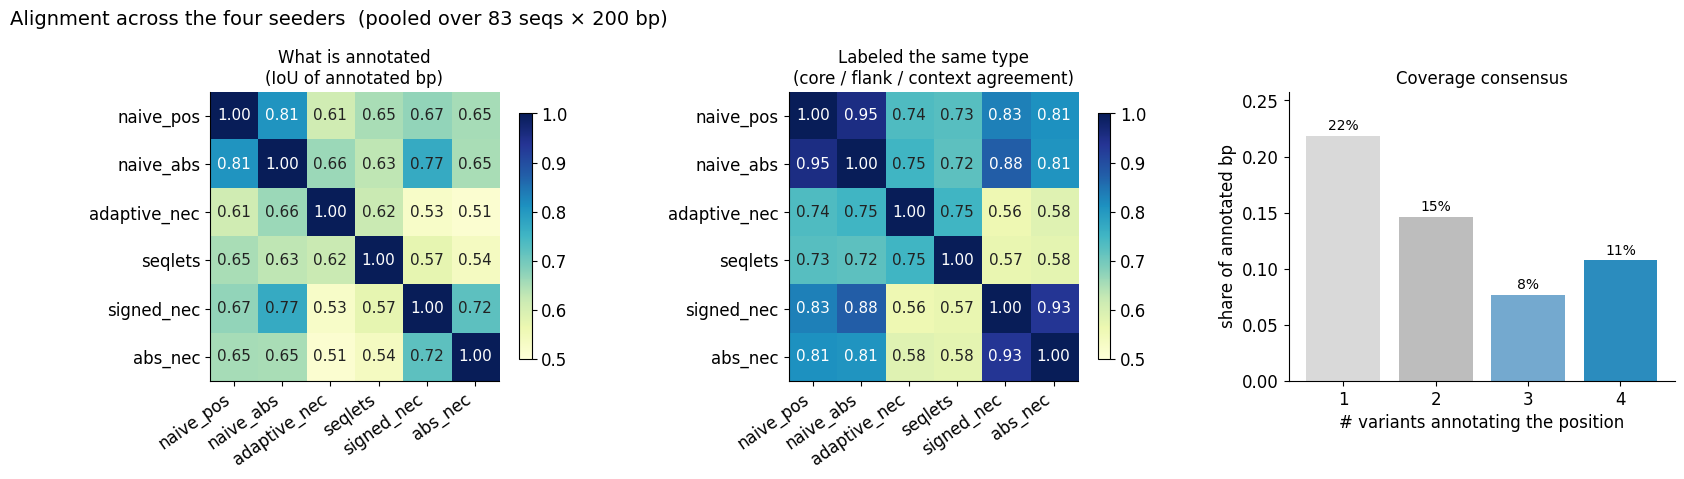

In [5]:
import pickle
L = 200
LABS = {'core': 1, 'flank': 2, 'context': 3}   # 0 = unannotated

lab_arr = {}
for v in ORDER:
    d = pickle.load(open(Path('results') / v / 'annotations.pkl', 'rb'))
    a = {}
    for sid, c in d['classified'].items():
        arr = np.zeros(L, np.int8)
        for k, code in LABS.items():
            for st, en in c.get(k, []):
                arr[st:en] = code
        a[sid] = arr
    lab_arr[v] = a

ids = sorted(set.intersection(*[set(lab_arr[v]) for v in ORDER]))
M = np.stack([np.concatenate([lab_arr[v][sid] for sid in ids]) for v in ORDER])  # (nvar, nseq*200)
ann = M > 0
n = len(ORDER)

iou = np.ones((n, n)); typ = np.ones((n, n))
for i in range(n):
    for j in range(n):
        u = (ann[i] | ann[j]).sum()
        iou[i, j] = (ann[i] & ann[j]).sum() / u if u else 1.0
        both = ann[i] & ann[j]
        typ[i, j] = ((M[i] == M[j]) & both).sum() / both.sum() if both.sum() else 1.0

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1, 1, 0.95]})
for ax, Mx, title in [(axes[0], iou, 'What is annotated\n(IoU of annotated bp)'),
                      (axes[1], typ, 'Labeled the same type\n(core / flank / context agreement)')]:
    im = ax.imshow(Mx, vmin=0.5, vmax=1.0, cmap='YlGnBu')
    ax.set_xticks(range(n)); ax.set_xticklabels(ORDER, rotation=35, ha='right')
    ax.set_yticks(range(n)); ax.set_yticklabels(ORDER)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f'{Mx[i, j]:.2f}', ha='center', va='center',
                    color='white' if Mx[i, j] > 0.78 else '#222', fontsize=11)
    ax.set_title(title, fontsize=12)
    fig.colorbar(im, ax=ax, fraction=0.046, shrink=0.85)

# coverage consensus: of positions annotated by >=1 variant, how many of the 4 agree
cov = ann.sum(0); anyann = cov > 0
frac = [(cov[anyann] == k).mean() for k in (1, 2, 3, 4)]
bars = axes[2].bar(['1', '2', '3', '4'], frac,
                   color=['#d9d9d9', '#bdbdbd', '#74a9cf', '#2b8cbe'])
for b, f in zip(bars, frac):
    axes[2].text(b.get_x() + b.get_width() / 2, f + 0.005, f'{f:.0%}', ha='center', fontsize=10)
axes[2].set_xlabel('# variants annotating the position'); axes[2].set_ylabel('share of annotated bp')
axes[2].set_title('Coverage consensus', fontsize=12); axes[2].set_ylim(0, max(frac) * 1.18)
for sp in ('top', 'right'):
    axes[2].spines[sp].set_visible(False)
fig.suptitle('Alignment across the four seeders  (pooled over %d seqs × 200 bp)' % len(ids),
             x=0.01, ha='left', fontsize=14)
plt.tight_layout(); plt.show()


## Post-sufficiency counter-element (repressor) rescue

Varying Stage-1 seeding did **not** fix the repressors: ~35% of repressive sequences still overshoot (Sufficiency > 100%) with every seeder, because the Stage-1 `nec > 0` gate discards repressor seeds no matter which seeder places them.

This section applies the **experimental logic gate** (`counter_element.py`, off by default — run `sbatch slurm/run_rescue.sbatch`): *after* sufficiency optimization, when the annotated set overshoots WT (`rec_final > 1 + tol`), seed candidates from the **opposite-sign CWM tail** (repressor for an over-activating seq, activator for an over-repressing one) and greedily add the one that pulls recovery back toward 100%, **keeping all existing annotations fixed**.

What to look for: overshoots pulled from ~120%/200% down to ~100%, with a **compact** counter-element bp (not a whole-sequence grab). Reads the `*_rescue` CSVs; if they're absent the cells print how to generate them.

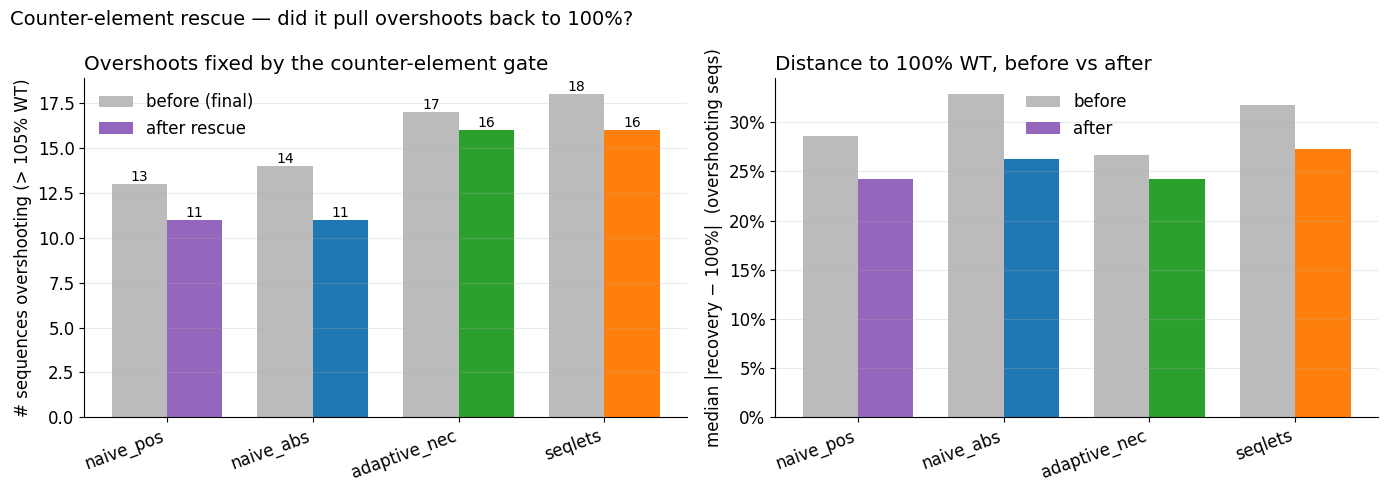

In [6]:
# Overshoot correction summary: how many overshoots the gate fixed, and how far toward 100%.
rpath = Path('results') / 'seed_comparison_rescue.csv'
TOL = 0.05
if not rpath.exists():
    print('No rescue outputs yet — run:  sbatch slurm/run_rescue.sbatch  (writes *_rescue CSVs)')
else:
    r = pd.read_csv(rpath)
    RORDER = [v for v in ORDER if v in set(r.variant)]
    over_b = r.rec_final > 1 + TOL          # overshot before the gate
    over_a = r.rec_rescued > 1 + TOL        # still overshooting after
    x = np.arange(len(RORDER)); w = 0.38
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    nb = [int((over_b & (r.variant == v)).sum()) for v in RORDER]
    na = [int((over_a & (r.variant == v)).sum()) for v in RORDER]
    axes[0].bar(x - w / 2, nb, w, color='#bbbbbb', label='before (final)')
    axes[0].bar(x + w / 2, na, w, color=[C[v] for v in RORDER], label='after rescue')
    for xi, (b_, a_) in enumerate(zip(nb, na)):
        axes[0].text(xi - w / 2, b_, b_, ha='center', va='bottom', fontsize=10)
        axes[0].text(xi + w / 2, a_, a_, ha='center', va='bottom', fontsize=10)
    axes[0].set_xticks(x); axes[0].set_xticklabels(RORDER, rotation=20, ha='right')
    axes[0].set_ylabel(f'# sequences overshooting (> {100 * (1 + TOL):.0f}% WT)')
    axes[0].set_title('Overshoots fixed by the counter-element gate', loc='left')
    axes[0].legend(frameon=False); axes[0].grid(axis='y', alpha=0.25)

    mb, ma = [], []
    for v in RORDER:
        g = r[(r.variant == v) & over_b]
        mb.append((g.rec_final - 1).abs().median() if len(g) else 0.0)
        ma.append((g.rec_rescued - 1).abs().median() if len(g) else 0.0)
    axes[1].bar(x - w / 2, mb, w, color='#bbbbbb', label='before')
    axes[1].bar(x + w / 2, ma, w, color=[C[v] for v in RORDER], label='after')
    axes[1].set_xticks(x); axes[1].set_xticklabels(RORDER, rotation=20, ha='right')
    axes[1].yaxis.set_major_formatter(pct)
    axes[1].set_ylabel('median |recovery − 100%|  (overshooting seqs)')
    axes[1].set_title('Distance to 100% WT, before vs after', loc='left')
    axes[1].legend(frameon=False); axes[1].grid(axis='y', alpha=0.25)
    fig.suptitle('Counter-element rescue — did it pull overshoots back to 100%?',
                 x=0.01, ha='left', fontsize=14)
    plt.tight_layout(); plt.show()

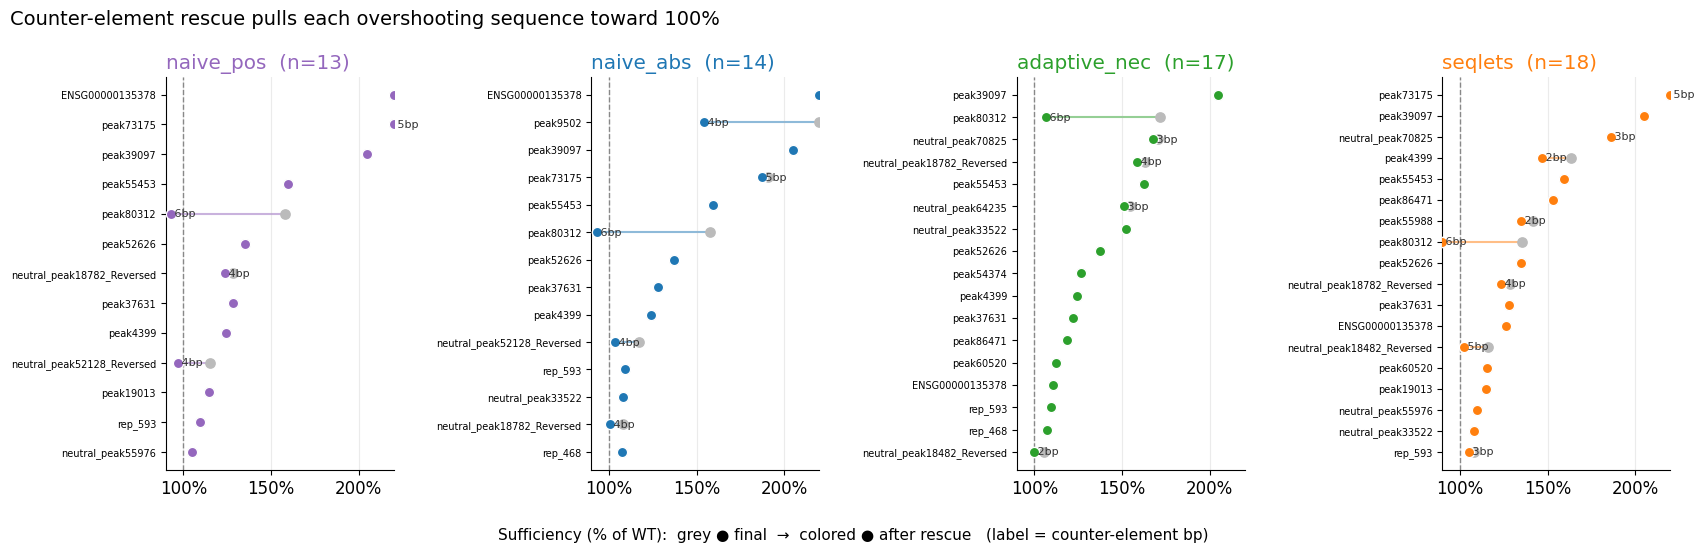

In [7]:
# Per-sequence dumbbells: recovery pulled from final (grey) -> after rescue (colored), per variant.
rpath = Path('results') / 'seed_comparison_rescue.csv'
TOL = 0.05
if not rpath.exists():
    print('No rescue outputs yet — run:  sbatch slurm/run_rescue.sbatch')
else:
    r = pd.read_csv(rpath)
    RORDER = [v for v in ORDER if v in set(r.variant)]
    XLIM = (0.9, 2.2)                        # clip the 200%+ cases into view
    fig, axes = plt.subplots(1, len(RORDER), figsize=(4.3 * len(RORDER), 5.5), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, v in zip(axes, RORDER):
        g = r[(r.variant == v) & (r.rec_final > 1 + TOL)].sort_values('rec_final')
        y = np.arange(len(g))
        for yi, (_, row) in zip(y, g.iterrows()):
            b_ = min(row.rec_final, XLIM[1])
            a_ = float(np.clip(row.rec_rescued, *XLIM))
            ax.plot([b_, a_], [yi, yi], color=C[v], lw=1.5, alpha=0.5, zorder=1)
            ax.scatter([b_], [yi], color='#bbbbbb', s=45, zorder=2)
            ax.scatter([a_], [yi], color=C[v], s=55, edgecolor='white', lw=1, zorder=3)
            if row.counter_bp > 0:
                ax.text(a_, yi, f' {int(row.counter_bp)}bp', va='center', fontsize=8, color='#333')
        ax.axvline(1.0, ls='--', color='#888', lw=1)
        ax.set_yticks(y); ax.set_yticklabels(g.seq_id, fontsize=7)
        ax.set_xlim(*XLIM); ax.xaxis.set_major_formatter(pct)
        ax.set_title(f'{v}  (n={len(g)})', loc='left', color=C[v])
        ax.grid(axis='x', alpha=0.25)
    fig.supxlabel('Sufficiency (% of WT):  grey ● final  →  colored ● after rescue   (label = counter-element bp)',
                  fontsize=11)
    fig.suptitle('Counter-element rescue pulls each overshooting sequence toward 100%',
                 x=0.01, ha='left', fontsize=14)
    plt.tight_layout(); plt.show()

## Zoom in on one sequence — attribution + where each seeder annotates

Full-window (200 bp) WT attribution and foreground logos over the per-seeder annotation track (core / flank / context), plus the rescue counter-element lane. Set `SEQ` to inspect any sequence; defaults to **peak55453** — the repressive case where the gate found nothing, because the strong feature in the map is a **repressor cluster (~bp 134–147)** while the annotated buffered feature sits to its left (~bp 111–125) and there is no positive/activator peak to seed a counter-element from.

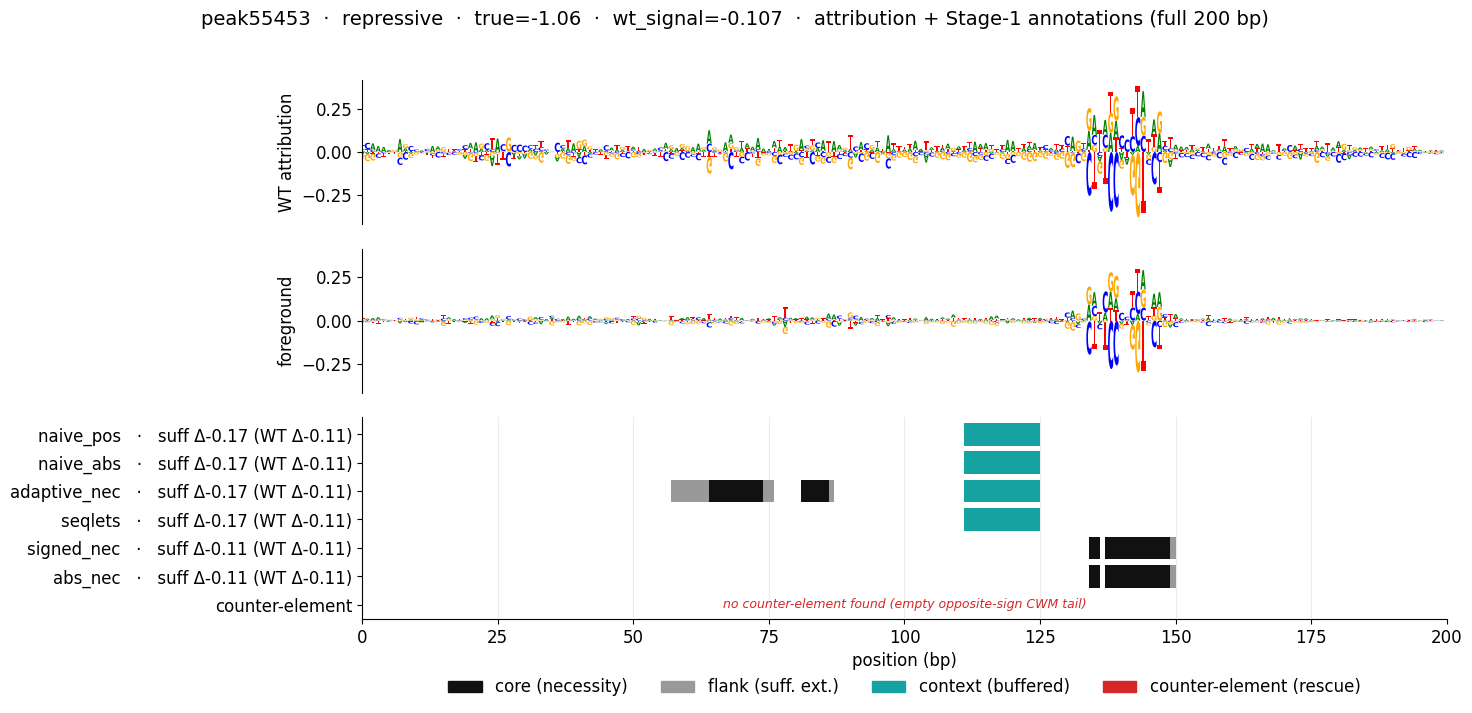

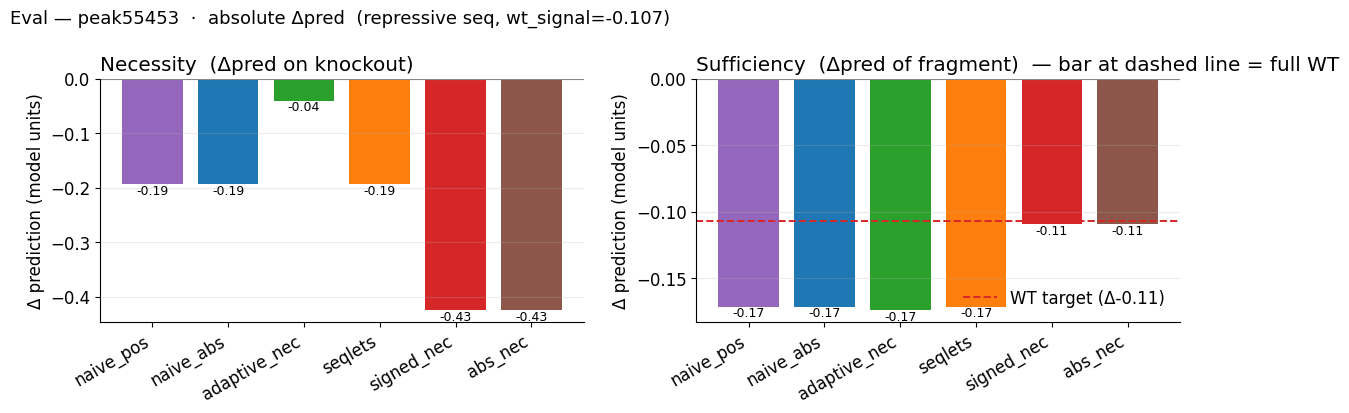

In [10]:
# Zoom: attribution logo + per-seeder annotation track + per-seeder eval metrics for one sequence.
import sys, pickle
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch

_BENCH = Path('/grid/koo/home/pmantill/projects/AutoSituate/k562_agft_benchmark')
if str(_BENCH) not in sys.path:
    sys.path.insert(0, str(_BENCH))
import config as BCFG                       # benchmark paths — NOT the C color dict above
if str(BCFG.EI_DIR) not in sys.path:
    sys.path.insert(0, str(BCFG.EI_DIR))
from fast_logo import fast_logo
from metrics import merge_regions           # bind directly: cell above rebinds M to an array

SEQ = 'peak55453'                           # <- change to inspect any sequence
SUBC = {'core': '#111111', 'flank': '#999999', 'context': '#17a2a2'}

wt = np.load(BCFG.FOREGROUNDS / SEQ / 'wt_attribution.npy').astype(float)
fg = np.load(BCFG.FOREGROUNDS / SEQ / 'foreground_scaled.npy').astype(float)
Lseq = wt.shape[0]
logos = [('WT attribution', wt), ('foreground', fg)]

def _load_ann(v):
    p = Path('results') / v / 'annotations_rescue.pkl'
    if not p.exists():
        p = Path('results') / v / 'annotations.pkl'
    return pickle.load(open(p, 'rb'))

cls_by_var, ce_by_var = {}, {}
for v in ORDER:
    d = _load_ann(v); i = d['ids'].index(SEQ)
    cls_by_var[v] = d['classified'][SEQ]
    ce_by_var[v] = (d['native'][i].get('counter') or {}).get('counter_elements', [])

row = s[s.seq_id == SEQ]
abin = row.activity_bin.iloc[0] if len(row) else '?'
true = float(row['true'].iloc[0]) if len(row) else float('nan')

# ---- eval metrics for THIS seq, in ABSOLUTE Δpred (model units) so tiny-WT ratios
# don't blow up. necessity = Δpred on knockout; sufficiency = fragment's own signal
# (rec_final * wt_signal); the WT target for sufficiency is wt_signal itself.
e = s[s.seq_id == SEQ].set_index('variant').reindex(ORDER)
wt_sig = e['wt_signal']
wt_target = wt_sig.iloc[0]
nec_d = e['necessity']                       # already absolute Δpred
suff_d = e['rec_final'] * wt_sig             # sufficiency in model units
def _suff_lane(v):                           # robust lane label (Δpred, no division)
    return f'Δ{suff_d[v]:+.2f} (WT Δ{wt_sig[v]:+.2f})'

fig = plt.figure(figsize=(14, 7))
gs = gridspec.GridSpec(3, 1, height_ratios=[2, 2, 2.8], hspace=0.15)
ax0 = None
ymax = np.abs(np.concatenate([wt, fg])).max() * 1.1
for rr, (label, vals) in enumerate(logos):
    ax = fig.add_subplot(gs[rr], sharex=ax0) if ax0 else fig.add_subplot(gs[rr])
    ax0 = ax0 or ax
    fast_logo(vals, ax, ylim=(-ymax, ymax))
    ax.set_ylabel(label); ax.tick_params(axis='x', bottom=False, labelbottom=False)
    for sp in ('top', 'right', 'bottom'):
        ax.spines[sp].set_visible(False)

axt = fig.add_subplot(gs[2], sharex=ax0)
for yi, v in enumerate(ORDER):                              # core on top of flank on top of context
    for kind in ('context', 'flank', 'core'):
        for a, b in merge_regions(cls_by_var[v].get(kind, [])):
            axt.broken_barh([(a, b - a)], (yi - 0.4, 0.8), facecolors=SUBC[kind], edgecolors='none')
ce = merge_regions([(c['start'], c['end']) for v in ORDER for c in ce_by_var[v]])
yce = len(ORDER)
for a, b in ce:
    axt.broken_barh([(a, b - a)], (yce - 0.4, 0.8), facecolors='#d62728', edgecolors='none')
if not ce:
    axt.text(Lseq / 2, yce, 'no counter-element found (empty opposite-sign CWM tail)',
             ha='center', va='center', fontsize=9, color='#d62728', style='italic')

lanes = [f'{v}   ·   suff {_suff_lane(v)}' for v in ORDER] + ['counter-element']
axt.set_yticks(range(len(lanes))); axt.set_yticklabels(lanes)
axt.set_ylim(len(lanes) - 0.5, -0.6)                       # invert so naive_pos is on top
axt.set_xlim(0, Lseq); axt.set_xlabel('position (bp)'); axt.grid(axis='x', alpha=0.25)
for sp in ('top', 'right'):
    axt.spines[sp].set_visible(False)
axt.legend(handles=[Patch(color=SUBC['core'], label='core (necessity)'),
                    Patch(color=SUBC['flank'], label='flank (suff. ext.)'),
                    Patch(color=SUBC['context'], label='context (buffered)'),
                    Patch(color='#d62728', label='counter-element (rescue)')],
           frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.22))
fig.suptitle(f'{SEQ}  ·  {abin}  ·  true={true:.2f}  ·  wt_signal={wt_target:.3f}  ·  '
             f'attribution + Stage-1 annotations (full 200 bp)',
             x=0.01, ha='left', fontsize=14)
plt.show()

# ---- eval metrics AS A FIGURE, absolute Δpred (no %-of-WT, nothing blows up) ----
figE, (axN, axS) = plt.subplots(1, 2, figsize=(12, 4.2))
xpos = np.arange(len(ORDER)); cols = [C[v] for v in ORDER]

axN.bar(xpos, nec_d.values, color=cols)
axN.axhline(0, color='#888', lw=0.8)
for xi, val in zip(xpos, nec_d.values):
    axN.text(xi, val, f'{val:+.2f}', ha='center',
             va='bottom' if val >= 0 else 'top', fontsize=9)
axN.set_title('Necessity  (Δpred on knockout)', loc='left')
axN.set_ylabel('Δ prediction (model units)')

axS.bar(xpos, suff_d.values, color=cols)
axS.axhline(0, color='#888', lw=0.8)
axS.axhline(wt_target, ls='--', color='#d62728', lw=1.4,
            label=f'WT target (Δ{wt_target:+.2f})')
for xi, val in zip(xpos, suff_d.values):
    axS.text(xi, val, f'{val:+.2f}', ha='center',
             va='bottom' if val >= 0 else 'top', fontsize=9)
axS.set_title('Sufficiency  (Δpred of fragment)  — bar at dashed line = full WT', loc='left')
axS.set_ylabel('Δ prediction (model units)')
axS.legend(frameon=False, loc='best')

for ax in (axN, axS):
    ax.set_xticks(xpos); ax.set_xticklabels(ORDER, rotation=30, ha='right')
    ax.grid(axis='y', alpha=0.25)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
figE.suptitle(f'Eval — {SEQ}  ·  absolute Δpred  (repressive seq, wt_signal={wt_target:+.3f})',
              x=0.01, ha='left', fontsize=13)
plt.tight_layout(); plt.show()